<a href="https://colab.research.google.com/github/Minimire/CROP-RECOMMENDATION-app/blob/main/%E1%88%9E%E1%8C%81%E1%88%8D_6_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (2200, 8)
Missing values: 0
Duplicate rows: 0
Crop classes: 22
Train shape: (1760, 7) | Test shape: (440, 7)


,Model,Accuracy,Precision,Recall,F1
0,Random Forest,99.55%,99.57%,99.55%,99.55%
1,XGBoost,98.64%,98.74%,98.64%,98.62%
2,K-Nearest Neighbors (k=5),97.95%,98.04%,97.95%,97.93%
3,Logistic Regression,97.27%,97.40%,97.27%,97.25%
4,Dummy Classifier,4.55%,0.21%,4.55%,0.40%


Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__n_estimators': 100}
Best CV accuracy: 0.9943

Held-out test metrics:


,Value
accuracy,0.9955
precision_macro,0.9957
recall_macro,0.9955
f1_macro,0.9955
top_3_accuracy,1.0000


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

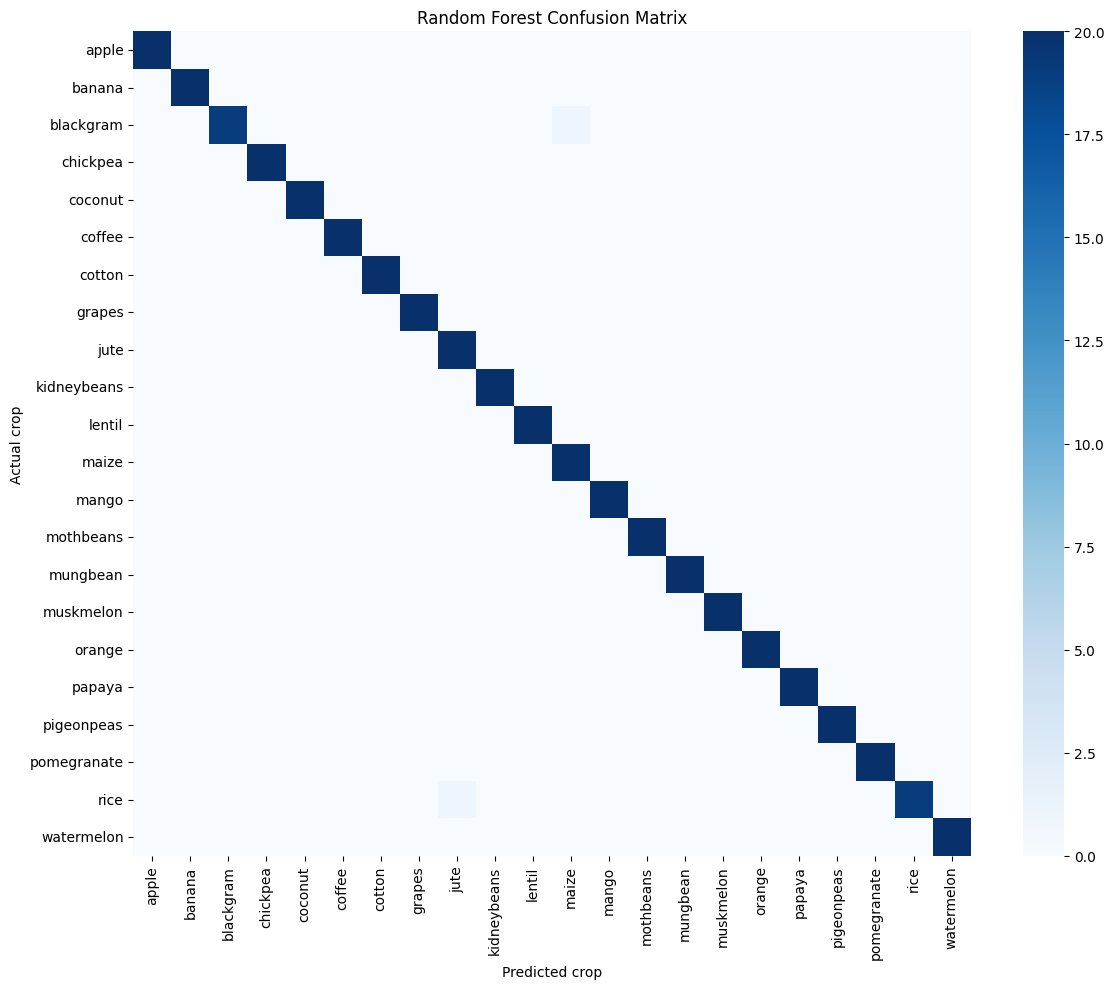

PSI demonstration (training split vs. held-out test split):


,Feature,PSI,Interpretation
0,N,0.0132,Little change
1,P,0.0227,Little change
2,K,0.0114,Little change
3,temperature,0.0507,Little change
4,humidity,0.0154,Little change
5,ph,0.0408,Little change
6,rainfall,0.0116,Little change



Created model file: /content/crop_recommendation_model.pkl


2026/11/16 16:47:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/16 16:47:59 INFO mlflow.store.db.utils: Updating database tables
2026/11/16 16:48:04 INFO mlflow.tracking.fluent: Experiment with name 'crop-recommendation-module-6' does not exist. Creating a new experiment.
2026/11/16 16:48:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



MLflow logging/registration did not complete: MlflowException('The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the \'skops_trusted_types\' parameter when calling \'log_model\' or \'save_model\' to the list of trusted types. Root error: Untrusted types found in the file: [\'sklearn.tree._tree.Tree\'].\n\n- sklearn.tree._tree.Tree: sklearn.tree._tree.Tree (the shared node storage for DecisionTree*, RandomForest*, ExtraTrees*, and GradientBoosting* models) stores raw node indices (left_child, right_child, feature) that scikit-learn indexes into without bounds checking. A malicious file can set these to out-of-range values: skops loads the object successfully, but calling .predict() on it can then crash the process (segfault) or read out-of-bounds memory. If you created the file yourself or otherwise fully trust its source, you can load it with trusted=["sklearn.tree._tree.Tree"].\n\nOnly add the specific types you have reviewed and tru

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


LIVE APP URL: https://alerts-auction-wires-monster.trycloudflare.com
Keep the Colab runtime running; this URL is temporary.

Finished. Check the Colab output for the .pkl download and live URL.
Artifacts are in the artifacts/ folder.


In [1]:

# SELF-CONTAINED GOOGLE COLAB CELL
# Trains and evaluates models, runs Random Forest GridSearchCV,
# creates README-related artifacts, saves/downloads a compatible .pkl,
# logs/registers the model with MLflow, and attempts to launch a temporary URL.

import os, sys, time, json, shutil, subprocess, urllib.request, re
from pathlib import Path

# Install dependencies
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "streamlit", "xgboost", "mlflow", "joblib", "scikit-learn",
     "pandas", "numpy", "matplotlib", "seaborn"],
    check=True
)

import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, top_k_accuracy_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

# -------------------- 1. Load and validate data --------------------

FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
SEED = 42
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

csv_file = Path("Crop_recommendation.csv")
xlsx_file = Path("Crop_recommendation.xlsx")
data_url = (
    "https://raw.githubusercontent.com/Gladiator07/Harvestify/"
    "master/Data-processed/crop_recommendation.csv"
)

if csv_file.exists():
    df = pd.read_csv(csv_file)
elif xlsx_file.exists():
    df = pd.read_excel(xlsx_file)
else:
    df = pd.read_csv(data_url)

missing_columns = sorted(set(FEATURES + [TARGET]) - set(df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing columns: {missing_columns}")

df = df[FEATURES + [TARGET]].dropna().copy()
if df.empty:
    raise ValueError("No data remains after removing missing rows.")

print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Crop classes:", df[TARGET].nunique())

X = df[FEATURES].copy()
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET])
class_names = list(label_encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

def make_pipeline(classifier):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier),
    ])

# -------------------- 2. Compare the README models --------------------

models = {
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
    ),
    "XGBoost": make_pipeline(
        XGBClassifier(
            n_estimators=200, learning_rate=0.1, max_depth=5,
            objective="multi:softprob", num_class=len(class_names),
            eval_metric="mlogloss", tree_method="hist",
            random_state=SEED, n_jobs=-1
        )
    ),
    "K-Nearest Neighbors (k=5)": make_pipeline(
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=2000, random_state=SEED)
    ),
    "Dummy Classifier": make_pipeline(
        DummyClassifier(strategy="most_frequent")
    ),
}

comparison_rows = []
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, pred, average="macro", zero_division=0),
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    "Accuracy", ascending=False
)
comparison.to_csv(ARTIFACTS / "model_comparison.csv", index=False)
display(comparison.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}",
    "Recall": "{:.2%}", "F1": "{:.2%}"
}))

# -------------------- 3. Tune Random Forest with GridSearchCV --------------------

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rf_pipeline = make_pipeline(
    RandomForestClassifier(random_state=SEED, n_jobs=-1)
)
param_grid = {
    "classifier__n_estimators": [100, 200, 500],
    "classifier__max_depth": [None, 10, 20],
    "classifier__max_features": ["sqrt", "log2"],
}

grid = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
)
grid.fit(X_train, y_train)
best_pipeline = grid.best_estimator_

print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

# -------------------- 4. Final test evaluation --------------------

test_pred = best_pipeline.predict(X_test)
test_proba = best_pipeline.predict_proba(X_test)

metrics = {
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "precision_macro": float(
        precision_score(y_test, test_pred, average="macro", zero_division=0)
    ),
    "recall_macro": float(
        recall_score(y_test, test_pred, average="macro", zero_division=0)
    ),
    "f1_macro": float(
        f1_score(y_test, test_pred, average="macro", zero_division=0)
    ),
    "top_3_accuracy": float(top_k_accuracy_score(
        y_test, test_proba, k=3,
        labels=np.arange(len(class_names))
    )),
}

print("\nHeld-out test metrics:")
display(pd.DataFrame([metrics]).T.rename(columns={0: "Value"}).round(4))

report = classification_report(
    y_test, test_pred, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0
)
(ARTIFACTS / "classification_report.txt").write_text(report, encoding="utf-8")
print(report)

# Save GridSearchCV results
grid_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
grid_results.to_csv(ARTIFACTS / "grid_search_results.csv", index=False)
(ARTIFACTS / "grid_search_results.txt").write_text(
    "Best parameters: " + json.dumps(grid.best_params_, default=str) +
    f"\nBest CV accuracy: {grid.best_score_:.6f}\n\n" +
    grid_results.head(5).to_string(index=False),
    encoding="utf-8",
)

# -------------------- 5. Confusion matrix and PSI --------------------

cm = confusion_matrix(y_test, test_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted crop")
plt.ylabel("Actual crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(ARTIFACTS / "confusion_matrix.png", dpi=180)
plt.show()

def calculate_psi(reference, current, bins=10):
    rows = []
    for col in FEATURES:
        ref = pd.to_numeric(reference[col], errors="coerce").dropna().to_numpy()
        cur = pd.to_numeric(current[col], errors="coerce").dropna().to_numpy()
        if len(ref) == 0 or len(cur) == 0:
            rows.append({"Feature": col, "PSI": np.nan})
            continue
        cuts = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)[1:-1]))
        edges = np.r_[-np.inf, cuts, np.inf]
        a = np.histogram(ref, bins=edges)[0].astype(float)
        b = np.histogram(cur, bins=edges)[0].astype(float)
        a = np.clip(a / max(a.sum(), 1), 1e-6, None)
        b = np.clip(b / max(b.sum(), 1), 1e-6, None)
        psi = float(np.sum((b - a) * np.log(b / a)))
        rows.append({
            "Feature": col,
            "PSI": psi,
            "Interpretation": (
                "Little change" if psi < 0.10 else
                "Moderate change" if psi < 0.25 else "Large change"
            )
        })
    return pd.DataFrame(rows)

# This is a demonstration comparison, not live production monitoring.
psi_report = calculate_psi(X_train, X_test)
psi_report.to_csv(ARTIFACTS / "psi_report.csv", index=False)
print("PSI demonstration (training split vs. held-out test split):")
display(psi_report.round(4))

# -------------------- 6. Save app-compatible model .pkl --------------------
# Your repository's app.py expects these exact keys and separately applies
# scaler.transform() before model.predict()/predict_proba().

scaler = best_pipeline.named_steps["scaler"]
model = best_pipeline.named_steps["classifier"]

artifact = {
    "model": model,
    "scaler": scaler,
    "label_encoder": label_encoder,
    "classes": class_names,
    "n_classes": len(class_names),
    "test_accuracy": metrics["accuracy"],

    # Metadata: describe the model and how it was trained
    "model_name": "CropRecommendationRandomForest",
    "model_version": "1.0.0",
    "training_date": "2026-11-16",  # Use the actual training date
    "feature_order": FEATURES,
    "dataset_rows": int(len(df)),
    "random_state": SEED,
    "best_parameters": grid.best_params_,
    "metrics": metrics,

    # Training-set summary for reference; this is not live PSI monitoring
    "baseline_stats": {
        feature: {
            "mean": float(X_train[feature].mean()),
            "std": float(X_train[feature].std(ddof=0)),
        }
        for feature in FEATURES
    },
}

joblib.dump(artifact, "crop_recommendation_model.pkl")

pkl_path = Path("crop_recommendation_model.pkl")
joblib.dump(artifact, pkl_path)
shutil.copy2(pkl_path, ARTIFACTS / pkl_path.name)
print(f"\nCreated model file: {pkl_path.resolve()}")

# -------------------- 7. Create model card --------------------

model_card = f"""# Crop Recommendation Model Card

- Model: Random Forest classifier
- Task: 22-class crop recommendation
- Features: {", ".join(FEATURES)}
- Dataset rows used: {len(df)}
- Training/test split: stratified 80/20, random_state={SEED}
- Tuning: GridSearchCV, stratified 5-fold CV
- Best parameters: {json.dumps(grid.best_params_, default=str)}
- Best CV accuracy: {grid.best_score_:.4f}
- Test accuracy: {metrics["accuracy"]:.4f}
- Test macro precision: {metrics["precision_macro"]:.4f}
- Test macro recall: {metrics["recall_macro"]:.4f}
- Test macro F1: {metrics["f1_macro"]:.4f}
- Test top-3 accuracy: {metrics["top_3_accuracy"]:.4f}

## Limitations
The training dataset is India-specific and does not establish suitability for
Ethiopian farms. Local agronomic data and field validation are required before
use for agricultural decisions. Model probabilities are not calibrated
confidence intervals. PSI here compares dataset splits and is not production
monitoring.
"""
(ARTIFACTS / "model_card.md").write_text(model_card, encoding="utf-8")

# -------------------- 8. MLflow tracking and model registry --------------------

try:
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("crop-recommendation-module-6")

    with mlflow.start_run(run_name="random-forest-gridsearch") as run:
        mlflow.log_param("model", "RandomForestClassifier")
        mlflow.log_param("training_rows", len(X_train))
        mlflow.log_param("test_rows", len(X_test))
        mlflow.log_param("best_parameters", json.dumps(grid.best_params_, default=str))
        mlflow.log_metric("best_cv_accuracy", float(grid.best_score_))
        for name, value in metrics.items():
            mlflow.log_metric(name, value)

        for file in ARTIFACTS.iterdir():
            if file.is_file():
                mlflow.log_artifact(str(file))

        mlflow.sklearn.log_model(
            best_pipeline,
            artifact_path="model",
            registered_model_name="CropRecommendationRandomForest",
        )
        print("\nMLflow run ID:", run.info.run_id)
        print("Registered model: CropRecommendationRandomForest")

except Exception as exc:
    print("\nMLflow logging/registration did not complete:", repr(exc))
    print("The .pkl and other artifacts are still saved if training succeeded.")

# -------------------- 9. Download the repository app and start it --------------------

app_url = (
    "https://raw.githubusercontent.com/"
    "Minimire/CROP-RECOMMENDATION-app/main/app.py"
)
try:
    urllib.request.urlretrieve(app_url, "app.py")
except Exception as exc:
    raise RuntimeError(f"Could not download the repository app.py: {exc}")

# Download model bundle to your device.
try:
    from google.colab import files
    files.download(str(pkl_path))
except Exception as exc:
    print("Automatic .pkl download failed:", repr(exc))
    print("In Colab, open the Files panel and download crop_recommendation_model.pkl.")

# Start Streamlit
streamlit_log = open("streamlit.log", "w")
streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
    ],
    stdout=streamlit_log,
    stderr=subprocess.STDOUT,
)
time.sleep(8)

if streamlit_process.poll() is not None:
    streamlit_log.flush()
    print("\nStreamlit did not start. Check streamlit.log in Colab Files.")
else:
    try:
        cloudflared_path = Path("/content/cloudflared")
        cloudflared_url = (
            "https://github.com/cloudflare/cloudflared/releases/latest/"
            "download/cloudflared-linux-amd64"
        )
        urllib.request.urlretrieve(cloudflared_url, cloudflared_path)
        cloudflared_path.chmod(0o755)

        tunnel_log = open("cloudflared.log", "w")
        tunnel_process = subprocess.Popen(
            [
                str(cloudflared_path), "tunnel",
                "--url", "http://127.0.0.1:8501",
                "--no-autoupdate",
            ],
            stdout=tunnel_log,
            stderr=subprocess.STDOUT,
        )

        live_url = None
        for _ in range(45):
            time.sleep(2)
            tunnel_log.flush()
            log_text = Path("cloudflared.log").read_text(
                encoding="utf-8", errors="ignore"
            )
            match = re.search(
                r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log_text
            )
            if match:
                live_url = match.group(0)
                break

        if live_url:
            print("\nLIVE APP URL:", live_url)
            print("Keep the Colab runtime running; this URL is temporary.")
        else:
            print("\nNo tunnel URL was detected.")
            print("Check cloudflared.log and streamlit.log in Colab Files.")

    except Exception as exc:
        print("\nCould not start Cloudflare Tunnel:", repr(exc))
        print("The .pkl may still have been created and downloaded.")

print("\nFinished. Check the Colab output for the .pkl download and live URL.")
print("Artifacts are in the artifacts/ folder.")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')